# PCA versus TICA: a worked two-feature example
**CSMP 150 — Markov state models: applications**

[Open in Colab](https://colab.research.google.com/github/paulrobustelli/CSMP_150_2026/blob/main/notebooks/PCA_TICA_Worked_Example.ipynb)

We will calculate a covariance matrix by hand, solve PCA, introduce time-lagged covariance, and solve TICA. Then we will recover the same results from a reproducible stochastic simulation.

**Question:** Does the direction with the largest fluctuations also have the slowest dynamics? This model deliberately makes the answer **no**.

Run all cells in order. Only NumPy, SciPy and Matplotlib are required; these are available in standard Colab. All time units are **simulation steps**, not nanoseconds. This is an exactly solvable stationary Gaussian AR(1) model, not molecular dynamics or a Metropolis trajectory.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eigh
from scipy.signal import lfilter
np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({"figure.dpi": 120, "font.size": 12,
                     "axes.spines.top": False, "axes.spines.right": False})
FAST, SLOW = "#d17b13", "#0072b2"
SEED = 20261112


## 1. Build a model with a large fast fluctuation and a small slow fluctuation
Let $f_n$ and $s_n$ be independent, zero-mean stationary processes:
$$f_{n+1}=0.2f_n+3\sqrt{1-0.2^2}\,\epsilon_{f,n},\qquad
s_{n+1}=0.95s_n+\sqrt{1-0.95^2}\,\epsilon_{s,n}.$$
Each $\epsilon$ is an independent standard normal random number. The noise amplitudes give $\operatorname{Var}(f)=9$ and $\operatorname{Var}(s)=1$. Their one-step correlations are 0.2 and 0.95.

We observe mixtures, not the latent coordinates:
$$x_n=6+f_n+s_n,\qquad y_n=2+f_n-s_n.$$
The mean is $\boldsymbol\mu=(6,2)^T$. For centered features $\mathbf z_n=(x_n-6,y_n-2)^T$,
$$\mathbf z_n=M\begin{pmatrix}f_n\\s_n\end{pmatrix},\qquad M=\begin{pmatrix}1&1\\1&-1\end{pmatrix}.$$

**In words:** a large, rapidly changing motion moves both features together. A smaller, persistent motion moves them in opposite directions.

In [2]:
M = np.array([[1., 1.], [1., -1.]])
mean_exact = np.array([6., 2.])
rho = np.array([0.2, 0.95])  # fast, slow
variance = np.array([9., 1.])
C0 = M @ np.diag(variance) @ M.T
C1 = M @ np.diag(variance * rho) @ M.T
print("Exact C0:\n", C0)
print("Exact C1:\n", C1)


Exact C0:
 [[10.  8.]
 [ 8. 10.]]
Exact C1:
 [[2.75 0.85]
 [0.85 2.75]]


## 2. Center four snapshots and calculate every covariance entry
For hand arithmetic, choose four illustrative snapshots:
$$X=\begin{pmatrix}10&4\\8&6\\4&-2\\2&0\end{pmatrix},\quad
\overline{\mathbf x}=(6,2),\quad Z=\begin{pmatrix}4&2\\2&4\\-2&-4\\-4&-2\end{pmatrix}.$$
Rows are snapshots; columns are features. These four points are **an arithmetic example, not a simulated trajectory**. Their row ordering does not define kinetics.

We use the moment convention $1/N$ throughout the hand calculation:
$$C_0=\frac{1}{4}Z^TZ=\frac14\begin{pmatrix}40&32\\32&40\end{pmatrix}
=\begin{pmatrix}10&8\\8&10\end{pmatrix}.$$
$$C_{0,11}=\frac{4^2+2^2+(-2)^2+(-4)^2}{4}=10,$$
$$C_{0,12}=\frac{(4)(2)+(2)(4)+(-2)(-4)+(-4)(-2)}{4}=8.$$
Similarly $C_{0,22}=10$ and $C_{0,21}=8$. The diagonal measures each feature's variance; the off-diagonal measures their tendency to fluctuate together. This $1/N$ convention differs from an unbiased $1/(N-1)$ sample covariance.

In [3]:
X_hand = np.array([[10., 4.], [8., 6.], [4., -2.], [2., 0.]])
Z = X_hand - X_hand.mean(axis=0)
print("Mean:", X_hand.mean(axis=0))
print("Centered snapshots:\n", Z)
print("Sum of outer products:\n", Z.T @ Z)
np.testing.assert_allclose(Z.T @ Z / len(Z), C0)


Mean: [6. 2.]
Centered snapshots:
 [[ 4.  2.]
 [ 2.  4.]
 [-2. -4.]
 [-4. -2.]]
Sum of outer products:
 [[40. 32.]
 [32. 40.]]


## 3. PCA: find the direction of largest variance
For a Euclidean unit vector $\mathbf v$, the projected coordinate is $q_n=\mathbf v^T\mathbf z_n$ and its variance is $\mathbf v^TC_0\mathbf v$.
$$C_0\mathbf v=\sigma^2\mathbf v,\qquad
\det(C_0-\sigma^2I)=(10-\sigma^2)^2-64=0.$$
The roots are 18 and 2:
$$\mathbf v_{\mathrm{PC1}}=\frac{1}{\sqrt2}\begin{pmatrix}1\\1\end{pmatrix},\quad
\mathbf v_{\mathrm{PC2}}=\frac{1}{\sqrt2}\begin{pmatrix}1\\-1\end{pmatrix}.$$
$$q_{\mathrm{PC1}}=\sqrt2 f,\quad q_{\mathrm{PC2}}=\sqrt2 s.$$
PC1 explains $18/(18+2)=90\%$ of the variance, but it is the **fast** coordinate. PCA does not use the ordering of frames.

In [4]:
pca_values, pca_vectors = eigh(C0)
pca_values, pca_vectors = pca_values[::-1], pca_vectors[:, ::-1]
# Fix an arbitrary eigenvector sign so the first entry is positive.
pca_vectors *= np.sign(pca_vectors[0])
print("PCA variances:", pca_values)
print("PCA vectors (columns):\n", pca_vectors)
print("Explained variance:", pca_values / pca_values.sum())
print("Four projected snapshots:\n", Z @ pca_vectors)
np.testing.assert_allclose(C0 @ pca_vectors, pca_vectors * pca_values)


PCA variances: [18.  2.]
PCA vectors (columns):
 [[ 0.70711  0.70711]
 [ 0.70711 -0.70711]]
Explained variance: [0.9 0.1]
Four projected snapshots:
 [[ 4.24264  1.41421]
 [ 4.24264 -1.41421]
 [-4.24264  1.41421]
 [-4.24264 -1.41421]]


## 4. Add time information: what remains correlated one step later?
The time-lagged covariance is
$$C_\tau=\mathbb E[\mathbf z_n\mathbf z_{n+\tau}^T].$$
For this reversible stationary model it is symmetric, and
$$C_\tau=M\operatorname{diag}(9\,0.2^\tau,\;0.95^\tau)M^T.$$
At $\tau=1$, $9(0.2)=1.8$ and $1(0.95)=0.95$, so
$$C_1=\begin{pmatrix}1.8+0.95&1.8-0.95\\1.8-0.95&1.8+0.95\end{pmatrix}
=\begin{pmatrix}2.75&0.85\\0.85&2.75\end{pmatrix}.$$

To work the multiplication with our four points, use their **conditional mean futures**, not individual noisy future observations:
$$\mathbb E[\mathbf z_{n+1}\mid\mathbf z_n]=A\mathbf z_n,\qquad
A=\begin{pmatrix}0.575&-0.375\\-0.375&0.575\end{pmatrix}.$$
$$\overline Y=ZA^T=\begin{pmatrix}1.55&-0.35\\-0.35&1.55\\0.35&-1.55\\-1.55&0.35\end{pmatrix}.$$
Averaging over future noise leaves these means. Then
$$\frac14 Z^T\overline Y=C_1,$$
$$C_{1,11}=(6.2-0.7-0.7+6.2)/4=2.75,\qquad
C_{1,12}=(-1.4+3.1+3.1-1.4)/4=0.85.$$
The conditional mean futures have less variance than actual future samples; do not treat them as an equilibrium trajectory.

In [5]:
A = M @ np.diag(rho) @ np.linalg.inv(M)
Y_mean = Z @ A.T
print("Conditional mean propagation A:\n", A)
print("Conditional mean futures:\n", Y_mean)
print("C1 from hand calculation:\n", Z.T @ Y_mean / 4)
np.testing.assert_allclose(Z.T @ Y_mean / 4, C1)


Conditional mean propagation A:
 [[ 0.575 -0.375]
 [-0.375  0.575]]
Conditional mean futures:
 [[ 1.55 -0.35]
 [-0.35  1.55]
 [ 0.35 -1.55]
 [-1.55  0.35]]
C1 from hand calculation:
 [[2.75 0.85]
 [0.85 2.75]]


## 5. Why diagonalizing the lagged covariance alone is not enough
The variance-dominated direction still has the larger raw lagged covariance:
$$\mathbf v_{\mathrm{PC1}}^TC_1\mathbf v_{\mathrm{PC1}}=3.6,\qquad
\mathbf v_{\mathrm{PC2}}^TC_1\mathbf v_{\mathrm{PC2}}=1.9.$$
But the fractions retained are $3.6/18=0.2$ and $1.9/2=0.95$.

TICA maximizes this **normalized time correlation**:
$$R(\mathbf v)=\frac{\mathbf v^TC_\tau\mathbf v}{\mathbf v^TC_0\mathbf v},\qquad
C_\tau\mathbf v_i=\lambda_i C_0\mathbf v_i.$$
Here $\mathbf v$ contains feature weights, $\lambda$ is lagged correlation, and $C_0$ provides the variance normalization. Successive coordinates are orthogonal in the covariance metric: $\mathbf v_i^TC_0\mathbf v_j=\delta_{ij}$.

We removed the mean, so there is no constant equilibrium coordinate in this two-feature calculation.

## 6. Solve the generalized eigenproblem explicitly
For hand arithmetic only,
$$C_0^{-1}=\frac1{36}\begin{pmatrix}10&-8\\-8&10\end{pmatrix},\qquad
C_0^{-1}C_1=\begin{pmatrix}0.575&-0.375\\-0.375&0.575\end{pmatrix}.$$
The characteristic equation is $(0.575-\lambda)^2-0.375^2=0$, giving 0.95 and 0.2. With unit projected variance:
$$\mathbf v_{\mathrm{TIC1}}=\frac12\begin{pmatrix}1\\-1\end{pmatrix},\quad
\mathbf v_{\mathrm{TIC2}}=\frac16\begin{pmatrix}1\\1\end{pmatrix}.$$
$$q_{\mathrm{TIC1}}=s,\qquad q_{\mathrm{TIC2}}=f/3.$$
For the slow mode, $C_1(0.5,-0.5)^T=(0.95,-0.95)^T=0.95 C_0(0.5,-0.5)^T$.

This example's $C_0^{-1}C_1$ happens to be symmetric because the matrices commute. That is **not true in general**. Numerically use the symmetric generalized solver `eigh(Ctau, C0)`, not an explicitly formed inverse.

In [6]:
tica_values, tica_vectors = eigh(C1, C0)
tica_values, tica_vectors = tica_values[::-1], tica_vectors[:, ::-1]
tica_vectors *= np.sign(tica_vectors[0])
print("TICA correlations:", tica_values)
print("Unit-variance TICA vectors (columns):\n", tica_vectors)
print("C0 metric check:\n", tica_vectors.T @ C0 @ tica_vectors)
print("Four TICA projections:\n", Z @ tica_vectors)
np.testing.assert_allclose(tica_values, [0.95, 0.2])
np.testing.assert_allclose(tica_vectors, [[0.5, 1/6], [-0.5, 1/6]])
np.testing.assert_allclose(C1 @ tica_vectors, C0 @ tica_vectors * tica_values, atol=1e-12)
np.testing.assert_allclose(tica_vectors.T @ C0 @ tica_vectors, np.eye(2), atol=1e-12)


TICA correlations: [0.95 0.2 ]
Unit-variance TICA vectors (columns):
 [[ 0.5      0.16667]
 [-0.5      0.16667]]
C0 metric check:
 [[ 1. -0.]
 [ 0.  1.]]
Four TICA projections:
 [[ 1.  1.]
 [-1.  1.]
 [ 1. -1.]
 [-1. -1.]]


## 7. Whitening gives an ordinary symmetric eigenproblem
Let $W=C_0^{-1/2}$ and $K=WC_\tau W$. Solve $K\mathbf w_i=\lambda_i\mathbf w_i$ and return to original feature coefficients with $\mathbf v_i=W\mathbf w_i$.

**In words:** first remove the unequal variance scales and correlations, then find the direction that remembers its past best. Whitening alone is not TICA: it does not use time order.

In [7]:
d, U = eigh(C0)
W = (U * (1 / np.sqrt(d))) @ U.T
K = W @ C1 @ W
print("Whitening W:\n", W)
print("Whitened covariance:\n", W @ C0 @ W)
print("Whitened lagged covariance K:\n", K)
np.testing.assert_allclose(W @ C0 @ W, np.eye(2), atol=1e-12)
np.testing.assert_allclose(eigh(K)[0][::-1], tica_values)


Whitening W:
 [[ 0.4714 -0.2357]
 [-0.2357  0.4714]]
Whitened covariance:
 [[1. 0.]
 [0. 1.]]
Whitened lagged covariance K:
 [[ 0.575 -0.375]
 [-0.375  0.575]]


## 8. Now simulate actual noisy trajectories
We start each latent variable in its stationary Gaussian distribution. The simulation has 200,000 frames and a fixed random seed. Every subsequent frame includes independent stochastic noise.

In [8]:
def simulate(n_frames=200_000, seed=SEED):
    rng = np.random.default_rng(seed)
    latent = np.empty((n_frames, 2))
    # Each column is filtered independently. The first innovation is a
    # stationary initial sample, so no artificial burn-in is necessary.
    for j in range(2):
        innovations = rng.normal(size=n_frames) * np.sqrt(variance[j] * (1-rho[j]**2))
        innovations[0] = rng.normal(scale=np.sqrt(variance[j]))
        latent[:, j] = lfilter([1.], [1., -rho[j]], innovations)
    return mean_exact + latent @ M.T, latent

X, latent = simulate()
print("Trajectory shape:", X.shape)
print("Observed mean:", X.mean(axis=0), "; exact:", mean_exact)


Trajectory shape: (200000, 2)
Observed mean: [6.01631 1.9843 ] ; exact: [6. 2.]


## 9. Estimate covariance from time-paired samples
At lag $\tau$, form paired rows $A_n=\mathbf x_n-\widehat{\boldsymbol\mu}$ and $B_n=\mathbf x_{n+\tau}-\widehat{\boldsymbol\mu}$. The mean is pooled over both endpoints. For our stationary reversible example we use
$$\widehat C_0=\frac{A^TA+B^TB}{2N_p},\qquad
\widehat C_\tau=\frac{A^TB+B^TA}{2N_p}.$$
$N_p$ is the number of pairs. Symmetrization imposes reversibility, which is appropriate for this model; it is not a universal assumption for driven systems. Overlapping pairs are correlated, so pair count is not an independent sample count.

In [9]:
def reversible_covariances(data, lag):
    if not isinstance(lag, (int, np.integer)) or not 0 < lag < len(data):
        raise ValueError("lag must be an integer between 1 and n_frames-1")
    left, right = data[:-lag], data[lag:]
    mu = (left.mean(axis=0) + right.mean(axis=0)) / 2
    left, right = left-mu, right-mu
    n = len(left)
    c0 = (left.T @ left + right.T @ right)/(2*n)
    ct = (left.T @ right + right.T @ left)/(2*n)
    return mu, c0, ct

def solve_tica(data, lag=1):
    mu, c0, ct = reversible_covariances(data, lag)
    if np.min(eigh(c0, eigvals_only=True)) <= 1e-10:
        raise ValueError("Covariance is singular; remove redundant features or whiten with a cutoff")
    values, vectors = eigh(ct, c0)
    values, vectors = values[::-1], vectors[:, ::-1]
    vectors *= np.where(vectors[0] < 0, -1, 1)
    return mu, c0, ct, values, vectors

mu_hat, C0_hat, C1_hat, lam_hat, V_hat = solve_tica(X)
print("Estimated C0:\n", C0_hat, "\nExact:\n", C0)
print("Estimated C1:\n", C1_hat, "\nExact:\n", C1)
print("Estimated correlations:", lam_hat, "\nExact:", tica_values)
print("Estimated vectors:\n", V_hat)


Estimated C0:
 [[10.00113  7.91338]
 [ 7.91338  9.98019]] 
Exact:
 [[10.  8.]
 [ 8. 10.]]
Estimated C1:
 [[2.80029 0.8121 ]
 [0.8121  2.77801]] 
Exact:
 [[2.75 0.85]
 [0.85 2.75]]
Estimated correlations: [0.95175 0.20114] 
Exact: [0.95 0.2 ]
Estimated vectors:
 [[ 0.49065  0.16614]
 [-0.49057  0.16808]]


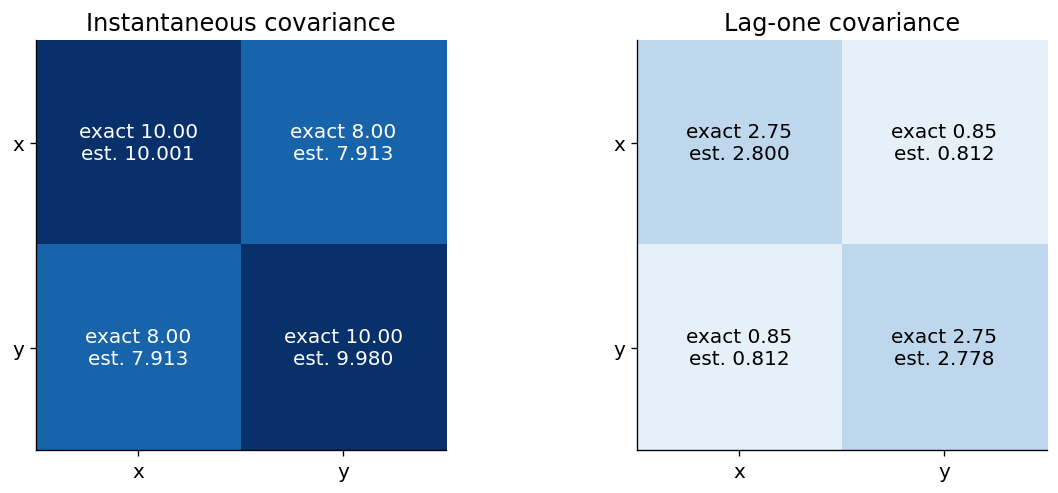

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
for ax, exact, estimate, title in zip(axes, [C0, C1], [C0_hat, C1_hat], ["Instantaneous covariance", "Lag-one covariance"]):
    ax.imshow(exact, cmap="Blues", vmin=0, vmax=10)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"exact {exact[i,j]:.2f}\nest. {estimate[i,j]:.3f}", ha="center", va="center", color="white" if exact[i,j]>6 else "black")
    ax.set(xticks=[0,1], yticks=[0,1], xticklabels=["x","y"], yticklabels=["x","y"], title=title)
plt.show()


## 10. Compare the directions and projected trajectories
PCA's first direction follows the long axis of the cloud. TICA's first direction follows the shorter but more persistent coordinate. The direction signs are arbitrary. We divide the leading PCA projection by its standard deviation only for the time-series comparison; this makes both displayed traces have unit variance.

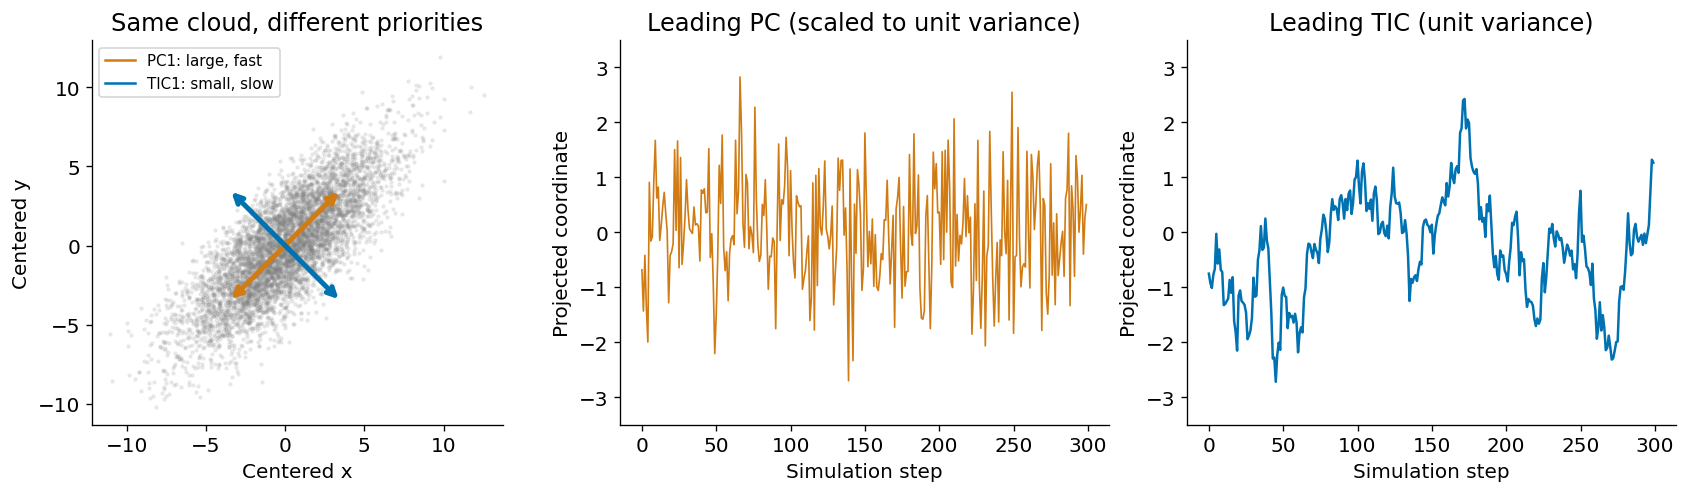

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), layout="constrained")
centered = X-mu_hat
axes[0].scatter(centered[:6000,0], centered[:6000,1], s=3, alpha=.12, color="gray")
for direction, color, label in [(pca_vectors[:,0], FAST, "PC1: large, fast"), (tica_vectors[:,0]/np.linalg.norm(tica_vectors[:,0]), SLOW, "TIC1: small, slow")]:
    tip = 5*direction
    axes[0].annotate("", xy=tip, xytext=-tip, arrowprops={"arrowstyle":"<->", "color":color, "lw":3})
    axes[0].plot([], [], color=color, label=label)
axes[0].set(xlabel="Centered x", ylabel="Centered y", aspect="equal", title="Same cloud, different priorities")
axes[0].legend(fontsize=9)
qfast = centered @ pca_vectors[:,0]/np.sqrt(pca_values[0])
qslow = centered @ V_hat[:,0]
axes[1].plot(qfast[:300], color=FAST, lw=1)
axes[2].plot(qslow[:300], color=SLOW, lw=1.5)
for ax, title in zip(axes[1:], ["Leading PC (scaled to unit variance)", "Leading TIC (unit variance)"]):
    ax.set(xlabel="Simulation step", ylabel="Projected coordinate", ylim=(-3.5,3.5), title=title)
plt.show()


## 11. Autocorrelation and implied relaxation times
For a positive mode eigenvalue, the exponential relaxation time is
$$t_i=-\frac{\tau}{\ln\lambda_i(\tau)}.$$
The exact values are $t_{\rm slow}\approx19.50$ and $t_{\rm fast}\approx0.621$ simulation steps. Because $\lambda_i(\tau)=\rho_i^\tau$, exact implied times do not depend on lag. At long lags the fast correlation is so small that sampling noise dominates; do not interpret negative/noisy estimates with the positive-eigenvalue logarithm formula.

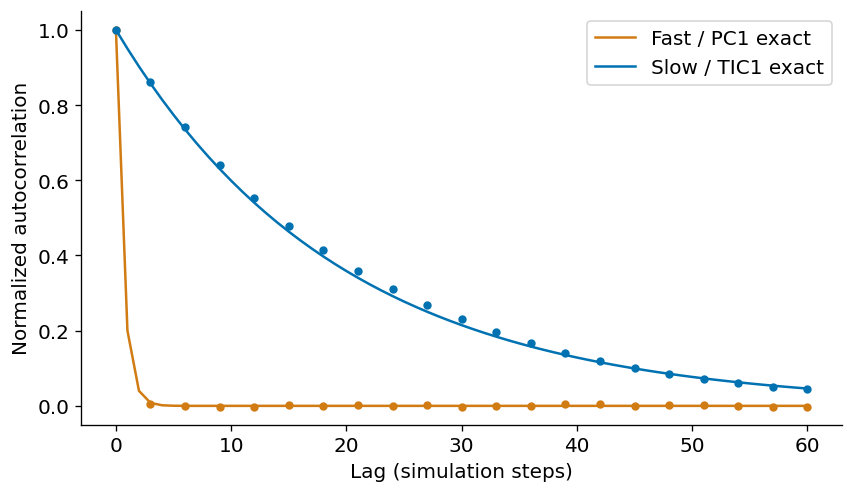

Exact slow, fast times: [19.49573  0.62133]
Estimated slow, fast times: [20.22144  0.62353]
lag    slow lambda    implied slow time    exact fast lambda
  1    0.951750       20.221              0.20000000
  2    0.905454       20.137              0.04000000
  3    0.861301       20.092              0.00800000
  5    0.780240       20.149              0.00032000
 10    0.608810       20.151              0.00000010
 20    0.377385       20.524              0.00000000


In [12]:
def acf(q, maxlag=60):
    q = q-q.mean()
    return np.array([np.mean(q[:len(q)-k]*q[k:])/np.mean(q*q) for k in range(maxlag+1)])

k = np.arange(61)
fig, ax = plt.subplots(figsize=(7,4), layout="constrained")
for q, r, color, label in [(qfast,.2,FAST,"Fast / PC1"),(qslow,.95,SLOW,"Slow / TIC1")]:
    ax.plot(k, r**k, color=color, label=label+" exact")
    ax.plot(k[::3], acf(q)[::3], "o", ms=4, color=color)
ax.set(xlabel="Lag (simulation steps)", ylabel="Normalized autocorrelation", ylim=(-.05,1.05))
ax.legend(); plt.show()
print("Exact slow, fast times:", -1/np.log(tica_values))
print("Estimated slow, fast times:", -1/np.log(lam_hat))

lags = np.array([1,2,3,5,10,20])
print("lag    slow lambda    implied slow time    exact fast lambda")
for lag in lags:
    values = solve_tica(X, int(lag))[3]
    print(f"{lag:3d}    {values[0]:.6f}       {-lag/np.log(values[0]):.3f}              {0.2**lag:.8f}")


## 12. Shuffle time as a control
Shuffle the same snapshots. The cloud and full-sample covariance are unchanged exactly (up to roundoff), but the correspondence between a frame and its next frame is lost. PCA is unchanged; lag-one TICA correlations collapse toward zero. The endpoint-paired covariance estimator can change very slightly because it excludes different endpoint frames.

Ordered correlations: [0.95175 0.20114]
Shuffled correlations: [ 0.00167 -0.00128]


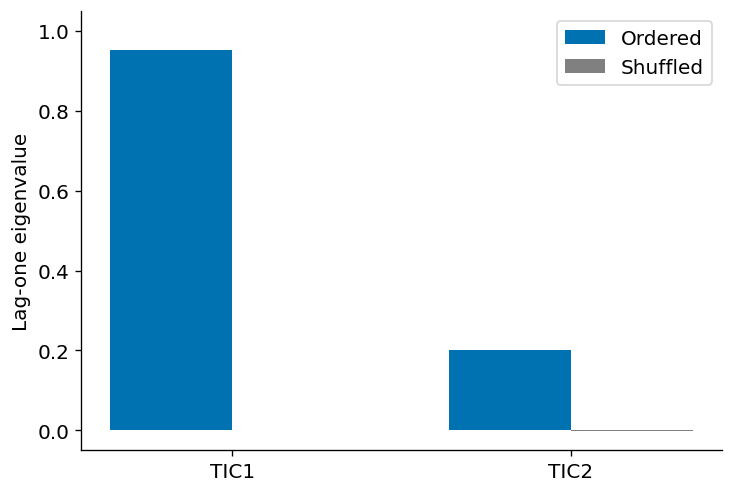

In [13]:
shuffled = X[np.random.default_rng(SEED+1).permutation(len(X))]
np.testing.assert_allclose(np.cov(X, rowvar=False, bias=True), np.cov(shuffled, rowvar=False, bias=True), atol=1e-12)
shuffle_lam = solve_tica(shuffled)[3]
print("Ordered correlations:", lam_hat)
print("Shuffled correlations:", shuffle_lam)
fig, ax = plt.subplots(figsize=(6,4), layout="constrained")
ax.bar(np.arange(2)-.18, lam_hat, width=.36, color=SLOW, label="Ordered")
ax.bar(np.arange(2)+.18, shuffle_lam, width=.36, color="gray", label="Shuffled")
ax.set(xticks=[0,1], xticklabels=["TIC1","TIC2"], ylabel="Lag-one eigenvalue", ylim=(-.05,1.05))
ax.legend(); plt.show()


## 13. Numerical checks
These checks test the exact hand calculation, covariance-metric normalization, generalized eigen-equations, statistical recovery, and the time-shuffle control. Statistical tolerances are deliberately looser than floating-point tolerances.

In [14]:
np.testing.assert_allclose(C0_hat, C0, rtol=.03, atol=.1)
np.testing.assert_allclose(C1_hat, C1, rtol=.05, atol=.1)
np.testing.assert_allclose(lam_hat, [.95,.2], atol=.015)
np.testing.assert_allclose(V_hat.T @ C0_hat @ V_hat, np.eye(2), atol=1e-12)
np.testing.assert_allclose(C1_hat @ V_hat, C0_hat @ V_hat * lam_hat, atol=1e-12)
assert abs(np.dot(V_hat[:,0], tica_vectors[:,0])/(np.linalg.norm(V_hat[:,0])*np.linalg.norm(tica_vectors[:,0]))) > .99
assert np.max(np.abs(shuffle_lam)) < .02
assert np.max(np.abs(lam_hat)) <= 1 + 1e-12
print("All exact and simulation checks passed.")


All exact and simulation checks passed.


## 14. From this toy model to protein features
In a protein trajectory, columns might be distances, contact features, or sine/cosine representations of dihedral angles. Centering and time pairing work in the same way, but the covariance matrices can have thousands of rows and columns. Redundant features require rank truncation or regularization. TICA finds the slowest **linear combinations in the supplied feature space**, not every possible nonlinear slow mode.

Try these modifications:
1. Increase the fast variance from 9 to 25. Predict how PCA and TICA change before rerunning.
2. Set both correlations to 0.95. Why does TICA no longer select a unique leading direction?
3. Reduce the trajectory to 1,000 frames and repeat over several seeds. Compare sampling variation.
4. Mix the features with an invertible non-orthogonal matrix. Verify that generalized eigenvalues are preserved, while coefficient vectors change.

**Sources:** [Pérez-Hernández et al. (2013), Identification of slow molecular order parameters for Markov model construction](https://arxiv.org/abs/1302.6614); [deeptime TICA documentation](https://deeptime-ml.github.io/latest/notebooks/tica.html). The numerical toy model and hand-calculation snapshots here are constructed for this lecture, not taken from the PNAS paper.